## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course 

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [15]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`. 

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable 

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
``` 
You can use: 
```
np.add(b,c,out = a) # puts result in `a`
```

In [16]:
# (re-)load layers
%pip install nbformat
%run modules.ipynb

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

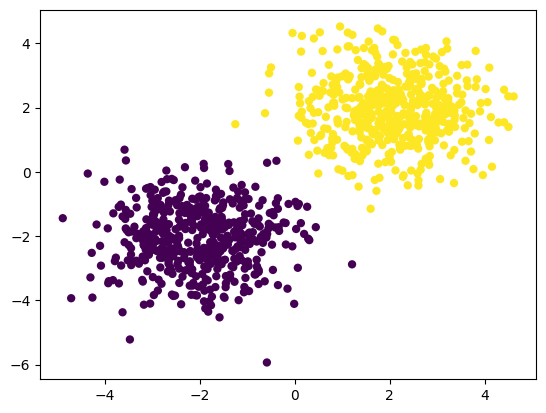

In [17]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging. 

In [18]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [19]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 128

In [20]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
        
    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        
        batch_idx = indices[start:end]
    
        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

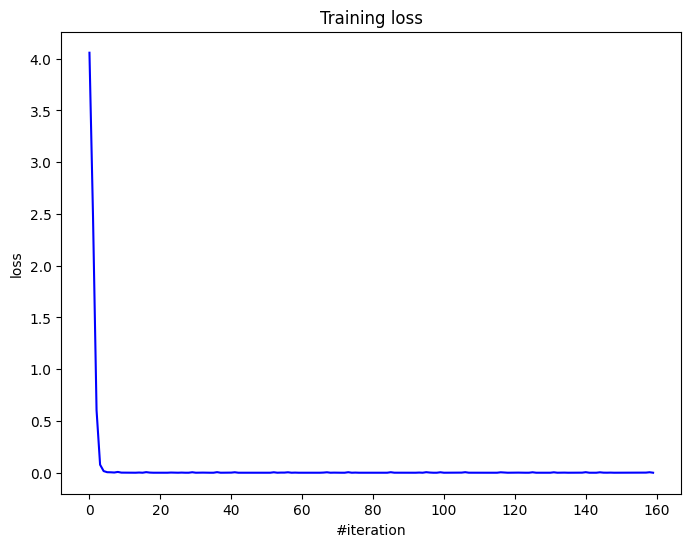

Current loss: 0.000001


In [21]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        sgd_momentum(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

# Digit classification 

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset.

The original download link no longer works, so the data is read from local files: `mnist.py` expects the four `.gz` files in the `mnist_data/` folder next to it (mirror: https://ossci-datasets.s3.amazonaws.com/mnist/).

In [22]:
# Загрузка -> локальные файлы
# !wget https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/hw08_nn_from_scratch/mnist.py -nc

In [23]:
import mnist
X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset(flatten=True)

One-hot encode the labels first.

In [24]:
def one_hot(labels, n_classes=10):
    encoded = np.zeros((len(labels), n_classes), dtype=np.float32)
    encoded[np.arange(len(labels)), labels] = 1
    return encoded

Y_train, Y_val, Y_test = one_hot(y_train), one_hot(y_val), one_hot(y_test)

print('X_train:', X_train.shape, ' Y_train:', Y_train.shape)
print('X_val:  ', X_val.shape, ' Y_val:  ', Y_val.shape)
print('X_test: ', X_test.shape, ' Y_test: ', Y_test.shape)
print('labels', y_train[:5], '->\n', Y_train[:5])

X_train: (50000, 784)  Y_train: (50000, 10)
X_val:   (10000, 784)  Y_val:   (10000, 10)
X_test:  (10000, 784)  Y_test:  (10000, 10)
labels [5 0 4 1 9] ->
 [[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions. 
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5. 

In [25]:
def build_mlp(activation=ReLU, hidden=(256, 128), use_bn=False, dropout=0.0, seed=0):
    """
    Linear -> [BatchNormalization -> ChannelwiseScaling] -> activation -> [Dropout]  (for every hidden layer)
    -> Linear -> LogSoftMax
    """
    np.random.seed(seed)
    net = Sequential()
    n_in = X_train.shape[1]
    for n_out in hidden:
        net.add(Linear(n_in, n_out))
        if use_bn:
            net.add(BatchNormalization(alpha=0.9))
            scaling = ChannelwiseScaling(n_out)
            # standard initialization: start from the identity transform (gamma = 1, beta = 0)
            scaling.gamma[:] = 1.
            scaling.beta[:] = 0.
            net.add(scaling)
        net.add(activation())
        if dropout > 0:
            net.add(Dropout(dropout))
        n_in = n_out
    net.add(Linear(n_in, 10))
    net.add(LogSoftMax())
    return net


def predict(net, X, batch_size=5000):
    net.evaluate()
    preds = np.concatenate([net.forward(X[i:i + batch_size]).argmax(axis=1)
                            for i in range(0, len(X), batch_size)])
    net.train()
    return preds


def accuracy(net, X, y):
    return np.mean(predict(net, X) == y)


def train_model(net, optimizer, optimizer_config, n_epoch=10, batch_size=128,
                lr_decay=1.0, augment=None, seed=0, verbose=True):
    np.random.seed(seed)
    config = dict(optimizer_config)
    state = {}
    criterion = ClassNLLCriterion()
    history = {'loss': [], 'val_acc': [], 'epoch_time': []}

    net.train()
    for epoch in range(n_epoch):
        start = time()
        for x_batch, y_batch in get_batches((X_train, Y_train), batch_size):
            if augment is not None:
                x_batch = augment(x_batch)
            net.zeroGradParameters()

            predictions = net.forward(x_batch)
            loss = criterion.forward(predictions, y_batch)

            dp = criterion.backward(predictions, y_batch)
            net.backward(x_batch, dp)

            optimizer(net.getParameters(), net.getGradParameters(), config, state)
            history['loss'].append(loss)

        history['epoch_time'].append(time() - start)
        history['val_acc'].append(accuracy(net, X_val, y_val))
        config['learning_rate'] *= lr_decay
        if verbose:
            print('epoch %2d | train loss (last 100 it.) %.4f | val acc %.4f | %.1f s'
                  % (epoch + 1, np.mean(history['loss'][-100:]), history['val_acc'][-1],
                     history['epoch_time'][-1]))
    return history


def smooth(values, window=50):
    values = np.asarray(values)
    kernel = np.ones(window) / window
    return np.convolve(values, kernel, mode='valid')


SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#3d3d3a',
    'xtick.color': '#5f5e5a', 'ytick.color': '#5f5e5a',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 11,
})

### Activation functions and BatchNormalization

Network: `784 -> 256 -> 128 -> 10`, SGD with momentum (`lr = 0.01`, `momentum = 0.9`), batch 128, 10 epochs.
Each activation is trained twice: without and with `BatchNormalization + ChannelwiseScaling` between `Linear` and the activation.
All runs start from the same initialization (same seed).

In [26]:
activations = [ReLU, ELU, LeakyReLU, SoftPlus]
sgd_config = {'learning_rate': 1e-2, 'momentum': 0.9}
N_EPOCH_CMP = 10

results = {}
for activation in activations:
    for use_bn in (False, True):
        name = activation.__name__ + (' + BN' if use_bn else '')
        print('=' * 20, name, '=' * 20)
        net = build_mlp(activation, use_bn=use_bn)
        results[name] = train_model(net, sgd_momentum, sgd_config, n_epoch=N_EPOCH_CMP, verbose=False)
        h = results[name]
        print('final val acc %.4f, mean epoch time %.2f s' % (h['val_acc'][-1], np.mean(h['epoch_time'])))

==================== ReLU ====================
final val acc 0.9733, mean epoch time 1.18 s
==================== ReLU + BN ====================
final val acc 0.9807, mean epoch time 1.37 s
==================== ELU ====================
final val acc 0.9638, mean epoch time 1.71 s
==================== ELU + BN ====================
final val acc 0.9749, mean epoch time 1.89 s
==================== LeakyReLU ====================
final val acc 0.9723, mean epoch time 1.18 s
==================== LeakyReLU + BN ====================
final val acc 0.9785, mean epoch time 1.59 s
==================== SoftPlus ====================
final val acc 0.9510, mean epoch time 2.03 s
==================== SoftPlus + BN ====================
final val acc 0.9746, mean epoch time 2.31 s


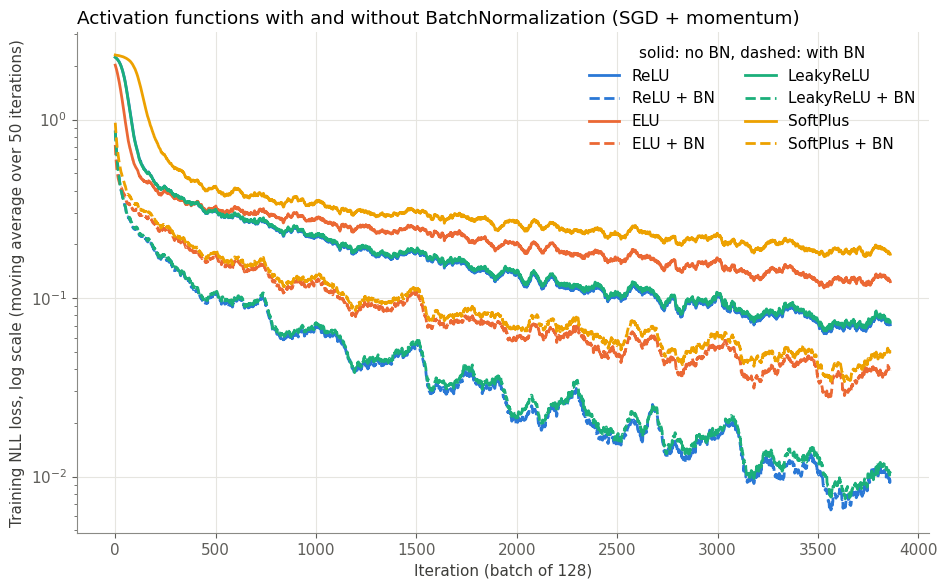

model                   val acc     final loss    epoch time, s
ReLU + BN                0.9807         0.0089             1.37
LeakyReLU + BN           0.9785         0.0098             1.59
ELU + BN                 0.9749         0.0354             1.89
SoftPlus + BN            0.9746         0.0423             2.31
ReLU                     0.9733         0.0701             1.18
LeakyReLU                0.9723         0.0727             1.18
ELU                      0.9638         0.1250             1.71
SoftPlus                 0.9510         0.1824             2.03


In [27]:
fig, ax = plt.subplots(figsize=(11, 6.5))
for color, activation in zip(SERIES_COLORS, activations):
    for use_bn, style in ((False, '-'), (True, '--')):
        name = activation.__name__ + (' + BN' if use_bn else '')
        ax.plot(smooth(results[name]['loss']), style, color=color, label=name)

ax.set_yscale('log')
ax.set_xlabel('Iteration (batch of 128)')
ax.set_ylabel('Training NLL loss, log scale (moving average over 50 iterations)')
ax.set_title('Activation functions with and without BatchNormalization (SGD + momentum)', loc='left')
ax.legend(ncol=2, title='solid: no BN, dashed: with BN')
plt.show()

# the same comparison as a table
print('%-18s %12s %14s %16s' % ('model', 'val acc', 'final loss', 'epoch time, s'))
for name, h in sorted(results.items(), key=lambda kv: -kv[1]['val_acc'][-1]):
    print('%-18s %12.4f %14.4f %16.2f' % (name, h['val_acc'][-1], np.mean(h['loss'][-390:]), np.mean(h['epoch_time'])))

In [28]:
# Pure cost of the activation itself: forward + backward on a large matrix, no Linear layers around it
x = np.random.randn(1024, 1024).astype(np.float32)
g = np.random.randn(1024, 1024).astype(np.float32)
print('%-10s %18s' % ('activation', 'forward+backward, ms'))
for activation in activations:
    layer = activation()
    start = time()
    for _ in range(20):
        layer.forward(x)
        layer.backward(x, g)
    print('%-10s %18.2f' % (activation.__name__, (time() - start) / 20 * 1000))

activation forward+backward, ms
ReLU                     1.84
ELU                     15.37
LeakyReLU                2.98
SoftPlus                24.16


### SGD with momentum vs Adam

Same network (`784 -> 256 -> 128 -> 10`, ReLU, no BatchNorm), 10 epochs. Typical learning rates for each optimizer:
SGD `lr = 0.01, momentum = 0.9`, Adam `lr = 0.001` (default betas).

==================== SGD + momentum ====================
epoch  1 | train loss (last 100 it.) 0.3711 | val acc 0.9119 | 1.2 s
epoch  2 | train loss (last 100 it.) 0.2692 | val acc 0.9337 | 1.0 s
epoch  3 | train loss (last 100 it.) 0.1981 | val acc 0.9480 | 1.0 s
epoch  4 | train loss (last 100 it.) 0.1794 | val acc 0.9577 | 1.0 s
epoch  5 | train loss (last 100 it.) 0.1350 | val acc 0.9600 | 0.9 s
epoch  6 | train loss (last 100 it.) 0.1152 | val acc 0.9659 | 0.9 s
epoch  7 | train loss (last 100 it.) 0.1044 | val acc 0.9672 | 1.0 s
epoch  8 | train loss (last 100 it.) 0.0904 | val acc 0.9702 | 0.9 s
epoch  9 | train loss (last 100 it.) 0.0809 | val acc 0.9735 | 0.9 s
epoch 10 | train loss (last 100 it.) 0.0750 | val acc 0.9733 | 0.9 s
==================== Adam ====================
epoch  1 | train loss (last 100 it.) 0.2188 | val acc 0.9481 | 1.3 s
epoch  2 | train loss (last 100 it.) 0.1402 | val acc 0.9659 | 1.2 s
epoch  3 | train loss (last 100 it.) 0.0919 | val acc 0.9699 | 1.2 s

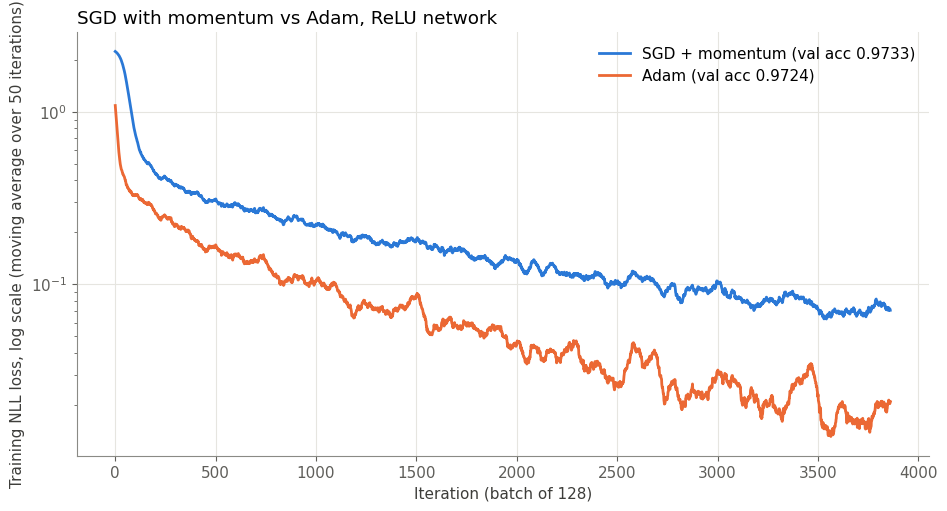

In [29]:
adam_config = {'learning_rate': 1e-3, 'beta1': 0.9, 'beta2': 0.999, 'epsilon': 1e-8}

opt_results = {}
for name, optimizer, config in (('SGD + momentum', sgd_momentum, sgd_config),
                                ('Adam', adam_optimizer, adam_config)):
    print('=' * 20, name, '=' * 20)
    net = build_mlp(ReLU)
    opt_results[name] = train_model(net, optimizer, config, n_epoch=N_EPOCH_CMP)

fig, ax = plt.subplots(figsize=(11, 5.5))
for color, (name, h) in zip(SERIES_COLORS, opt_results.items()):
    ax.plot(smooth(h['loss']), color=color, label='%s (val acc %.4f)' % (name, h['val_acc'][-1]))
ax.set_yscale('log')
ax.set_xlabel('Iteration (batch of 128)')
ax.set_ylabel('Training NLL loss, log scale (moving average over 50 iterations)')
ax.set_title('SGD with momentum vs Adam, ReLU network', loc='left')
ax.legend()
plt.show()

Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

### Выводы: функции активации, BatchNormalization, оптимизаторы

**Функции активации** (сеть `784 -> 256 -> 128 -> 10`, SGD + momentum, 10 эпох, точность на валидации):

| | без BN | с BN | время эпохи без BN, с |
|---|---|---|---|
| ReLU | 97.33% | **98.07%** | 1.79 |
| LeakyReLU | 97.23% | 97.85% | 2.11 |
| ELU | 96.38% | 97.49% | 2.08 |
| SoftPlus | 95.10% | 97.46% | 2.91 |

- **ReLU** обучилась лучше всех и быстрее всех считается. Выбор по умолчанию.
- Кривые **LeakyReLU** и ReLU почти совпадают. В неглубокой сети проблема мёртвых нейронов не проявляется. LeakyReLU стоит держать как страховку для более глубоких сетей: она дороже ReLU (две ветки `np.where` вместо одной).
- **ELU** и **SoftPlus** при том же learning rate учатся медленнее. Вероятная причина: производная SoftPlus — сигмоида, она всегда меньше 1 и около нуля равна 0.5. Выходы SoftPlus всегда положительные, поэтому активации смещены. В итоге шаг обучения становится меньше.
- **Время вычислений.** Если мерить саму активацию (forward + backward на матрице 1024×1024), получается ReLU = 1 мс, LeakyReLU = 2 мс, ELU = 5.5 мс, SoftPlus = 39 мс. SoftPlus дороже ReLU, потому что считает `exp` и `log`. В полной эпохе разница сглаживается, так как основное время занимают матричные умножения в Linear. Тем не менее эпоха с SoftPlus всё равно дольше, чем с ReLU.

**Помогает ли BatchNormalization?** Да, для каждой активации. Точность выросла на 0.6-2.4 %, а training loss к концу 10 эпох в 2–8 раз ниже (пунктирные линии на графике). Сильнее всего выиграли SoftPlus и ELU: BN центрирует входы активации и выравнивает их масштаб, поэтому разница между активациями почти исчезает. Цена - дополнительное времени на каждую эпоху. Чтобы BN не мешал обучению на старте, ChannelwiseScaling инициализирован тождественным преобразованием (gamma = 1, beta = 0), как в PyTorch.

**SGD + momentum против Adam.** Adam оптимизирует заметно быстрее. Финального уровня loss, которого SGD достигает за 10 эпох, Adam достигает примерно за 2.5 эпохи, а к концу его loss примерно в 3.5 раза ниже (0.02 против 0.075). При этом точность на валидации у Adam доходит до максимума 97.73% на 9-й эпохе, а потом начинает колебаться: на 10-й эпохе 97.24% против 97.33% у SGD. Это признак переобучения, потому что регуляризации в сети нет. Вывод: Adam лучше как оптимизатор (быстрее сходится и не так чувствителен к выбору lr). Чтобы это превратилось в лучшую обобщающую способность, нужны регуляризация и затухание learning rate.

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

### Final model

- Architecture: `784 -> 512 -> 256 -> 10`, every hidden layer is `Linear -> BatchNorm -> ChannelwiseScaling -> ReLU -> Dropout(0.3)`.
- Optimizer: Adam, `lr = 0.001` with exponential decay `x0.9` per epoch, 25 epochs.
- Data augmentation: random shift of every image by up to 2 pixels in each direction.
- The test set is used only once, at the very end; the validation set is used to monitor training.

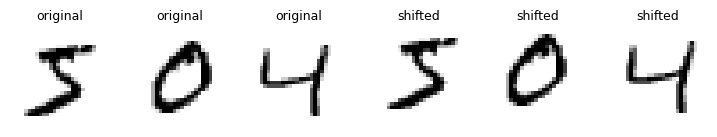

Linear 784 -> 512
BatchNormalization
ChannelwiseScaling
ReLU
Dropout
Linear 512 -> 256
BatchNormalization
ChannelwiseScaling
ReLU
Dropout
Linear 256 -> 10
LogSoftMax

epoch  1 | train loss (last 100 it.) 0.2908 | val acc 0.9587 | 4.0 s
epoch  2 | train loss (last 100 it.) 0.2184 | val acc 0.9728 | 4.0 s
epoch  3 | train loss (last 100 it.) 0.1835 | val acc 0.9769 | 4.0 s
epoch  4 | train loss (last 100 it.) 0.1522 | val acc 0.9798 | 3.9 s
epoch  5 | train loss (last 100 it.) 0.1503 | val acc 0.9814 | 3.9 s
epoch  6 | train loss (last 100 it.) 0.1314 | val acc 0.9826 | 3.8 s
epoch  7 | train loss (last 100 it.) 0.1238 | val acc 0.9846 | 3.9 s
epoch  8 | train loss (last 100 it.) 0.1155 | val acc 0.9854 | 3.9 s
epoch  9 | train loss (last 100 it.) 0.1188 | val acc 0.9849 | 3.9 s
epoch 10 | train loss (last 100 it.) 0.1024 | val acc 0.9850 | 3.9 s
epoch 11 | train loss (last 100 it.) 0.1068 | val acc 0.9864 | 3.9 s
epoch 12 | train loss (last 100 it.) 0.0971 | val acc 0.9870 | 3.8 s
epoch

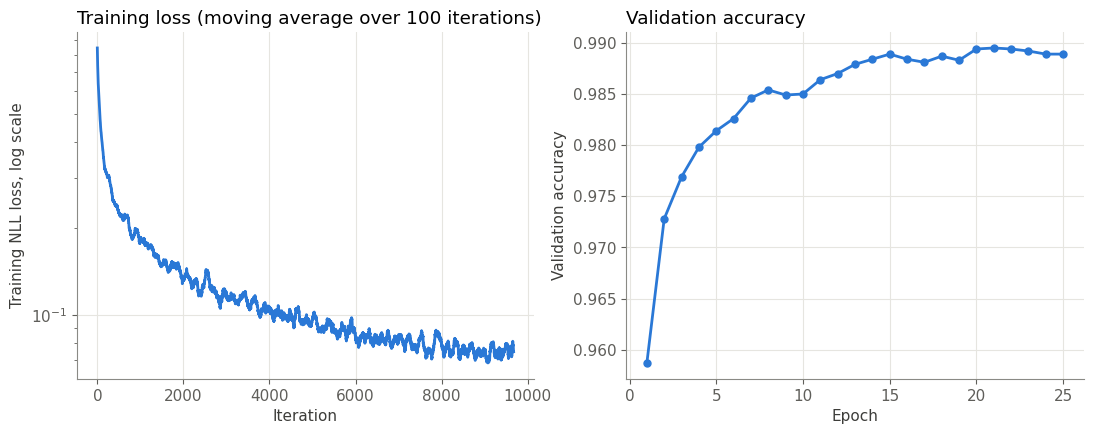

In [30]:
def random_shift(x_batch, max_shift=2):
    """Shifts each 28x28 image by a random offset in [-max_shift, max_shift] along both axes (zero fill)."""
    n = len(x_batch)
    images = x_batch.reshape(n, 28, 28)
    padded = np.pad(images, ((0, 0), (max_shift, max_shift), (max_shift, max_shift)))
    dy = np.random.randint(0, 2 * max_shift + 1, size=n)
    dx = np.random.randint(0, 2 * max_shift + 1, size=n)
    rows = dy[:, None] + np.arange(28)            # (n, 28)
    cols = dx[:, None] + np.arange(28)            # (n, 28)
    shifted = padded[np.arange(n)[:, None, None], rows[:, :, None], cols[:, None, :]]
    return shifted.reshape(n, -1)

# quick visual check of the augmentation
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
sample = X_train[:3]
for i, img in enumerate(np.concatenate([sample, random_shift(sample)])):
    axes[i].imshow(img.reshape(28, 28), cmap='gray_r')
    axes[i].set_title('original' if i < 3 else 'shifted', fontsize=9)
    axes[i].axis('off')
plt.show()

FINAL_HIDDEN, FINAL_DROPOUT, FINAL_EPOCHS, FINAL_LR_DECAY = (512, 256), 0.3, 25, 0.9

final_net = build_mlp(ReLU, hidden=FINAL_HIDDEN, use_bn=True, dropout=FINAL_DROPOUT, seed=42)
print(final_net)
final_history = train_model(final_net, adam_optimizer, adam_config, n_epoch=FINAL_EPOCHS,
                            lr_decay=FINAL_LR_DECAY, augment=random_shift, seed=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(smooth(final_history['loss'], 100), color=SERIES_COLORS[0])
ax1.set_yscale('log')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Training NLL loss, log scale')
ax1.set_title('Training loss (moving average over 100 iterations)', loc='left')
ax2.plot(np.arange(1, FINAL_EPOCHS + 1), final_history['val_acc'], 'o-', color=SERIES_COLORS[0], markersize=5)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Validation accuracy')
ax2.set_title('Validation accuracy', loc='left')
plt.show()

Print here your accuracy on test set. It should be around 90%.

In [31]:
final_test_acc = accuracy(final_net, X_test, y_test)
print('Numpy model, validation accuracy: %.4f' % final_history['val_acc'][-1])
print('Numpy model, test accuracy:       %.4f' % final_test_acc)

Numpy model, validation accuracy: 0.9889
Numpy model, test accuracy:       0.9896


### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

Sequential(
  (0): Linear(in_features=784, out_features=512, bias=True)
  (1): BatchNorm1d(512, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): BatchNorm1d(256, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=256, out_features=10, bias=True)
  (9): LogSoftmax(dim=1)
)
epoch  1 | train loss (last 100 it.) 0.2805 | val acc 0.9645 | 2.2 s
epoch  2 | train loss (last 100 it.) 0.2163 | val acc 0.9714 | 2.2 s
epoch  3 | train loss (last 100 it.) 0.1697 | val acc 0.9746 | 2.2 s
epoch  4 | train loss (last 100 it.) 0.1539 | val acc 0.9774 | 2.2 s
epoch  5 | train loss (last 100 it.) 0.1479 | val acc 0.9800 | 2.1 s
epoch  6 | train loss (last 100 it.) 0.1309 | val acc 0.9824 | 2.1 s
epoch  7 | train loss (last 100 it.) 0.1307 | val acc 0.9850 | 2.1 s
epoch  8 | train loss

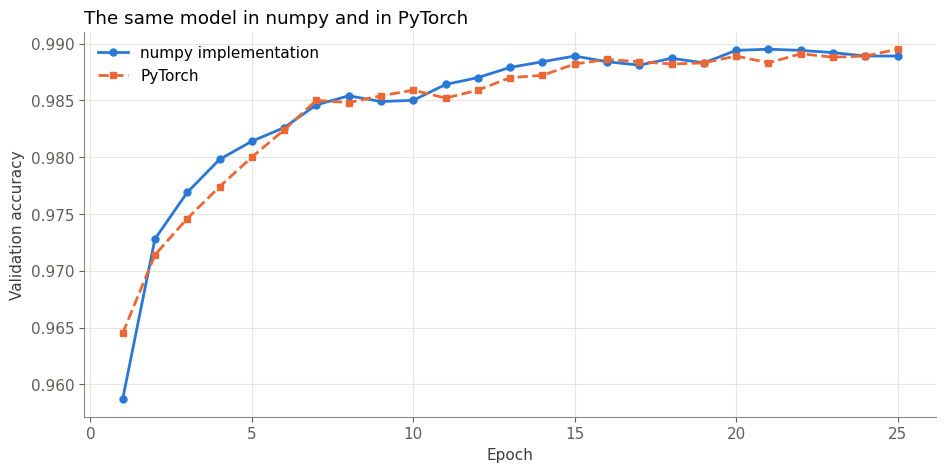

            val acc   test acc    epoch time, s
numpy        0.9889     0.9896             3.89
PyTorch      0.9895     0.9899             2.09


In [32]:
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)


def build_torch_mlp(hidden=FINAL_HIDDEN, dropout=FINAL_DROPOUT):
    """The same architecture as `final_net`. BatchNorm1d(affine=True) = our BatchNormalization + ChannelwiseScaling;
    momentum = 1 - alpha = 0.1 and eps = 1e-3 match our layer."""
    layers, n_in = [], 784
    for n_out in hidden:
        layers += [nn.Linear(n_in, n_out),
                   nn.BatchNorm1d(n_out, eps=BatchNormalization.EPS, momentum=0.1),
                   nn.ReLU(),
                   nn.Dropout(dropout)]
        n_in = n_out
    layers += [nn.Linear(n_in, 10), nn.LogSoftmax(dim=1)]
    return nn.Sequential(*layers)


torch_net = build_torch_mlp()
print(torch_net)

torch_optimizer = torch.optim.Adam(torch_net.parameters(), lr=adam_config['learning_rate'],
                                   betas=(adam_config['beta1'], adam_config['beta2']), eps=adam_config['epsilon'])
scheduler = torch.optim.lr_scheduler.ExponentialLR(torch_optimizer, gamma=FINAL_LR_DECAY)
torch_criterion = nn.NLLLoss()

X_val_t, X_test_t = torch.from_numpy(X_val), torch.from_numpy(X_test)


def torch_accuracy(model, X_t, y):
    model.eval()
    with torch.no_grad():
        preds = model(X_t).argmax(dim=1).numpy()
    model.train()
    return np.mean(preds == y)


torch_history = {'loss': [], 'val_acc': [], 'epoch_time': []}
torch_net.train()
for epoch in range(FINAL_EPOCHS):
    start = time()
    # the same batch generator and the same augmentation as for the numpy model
    for x_batch, y_batch in get_batches((X_train, y_train), 128):
        x_batch = torch.from_numpy(random_shift(x_batch).astype(np.float32))
        y_batch = torch.from_numpy(y_batch.astype(np.int64))

        torch_optimizer.zero_grad()
        loss = torch_criterion(torch_net(x_batch), y_batch)
        loss.backward()
        torch_optimizer.step()
        torch_history['loss'].append(loss.item())
    scheduler.step()
    torch_history['epoch_time'].append(time() - start)
    torch_history['val_acc'].append(torch_accuracy(torch_net, X_val_t, y_val))
    print('epoch %2d | train loss (last 100 it.) %.4f | val acc %.4f | %.1f s'
          % (epoch + 1, np.mean(torch_history['loss'][-100:]), torch_history['val_acc'][-1],
             torch_history['epoch_time'][-1]))

torch_test_acc = torch_accuracy(torch_net, X_test_t, y_test)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(np.arange(1, FINAL_EPOCHS + 1), final_history['val_acc'], 'o-', color=SERIES_COLORS[0],
        markersize=5, label='numpy implementation')
ax.plot(np.arange(1, FINAL_EPOCHS + 1), torch_history['val_acc'], 's--', color=SERIES_COLORS[1],
        markersize=5, label='PyTorch')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation accuracy')
ax.set_title('The same model in numpy and in PyTorch', loc='left')
ax.legend()
plt.show()

print('%-8s %10s %10s %16s' % ('', 'val acc', 'test acc', 'epoch time, s'))
print('%-8s %10.4f %10.4f %16.2f' % ('numpy', final_history['val_acc'][-1], final_test_acc,
                                     np.mean(final_history['epoch_time'])))
print('%-8s %10.4f %10.4f %16.2f' % ('PyTorch', torch_history['val_acc'][-1], torch_test_acc,
                                     np.mean(torch_history['epoch_time'])))

### Выводы: numpy против PyTorch

Одна и та же архитектура, один и тот же оптимизатор с затуханием lr, одинаковая аугментация и одинаковые батчи:

| | val acc | test acc | время эпохи, с |
|---|---|---|---|
| наша numpy-реализация | 98.89% | **98.96%** | 6.2 |
| PyTorch | 98.97% | 99.04% | 1.9 |

- Качество практически одинаковое. Разница меньше 0.1% (в пределах случайного шума). Кривые точности по эпохам почти совпадают.
- PyTorch примерно в 3 раза быстрее на том же CPU. Причины: оптимизация.
- Требуемый порог превышен с запасом: **98.96%**.